In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC

warnings.filterwarnings("ignore")

# input dari Data Preparation, fitur sama dengan ANN (angka diskalakan dan 300 kata TF-IDF)
data = pd.read_csv("../data/kbbi_bersih.csv")
data["contoh"] = data["contoh"].fillna("")
data["suku_kata"] = data["nama"].str.count(r"\.") + 1
data["huruf"] = data["nama"].str.replace(".", "", regex=False).str.len()
data["panjang_makna"] = data["submakna"].str.len()
data["jumlah_kata_makna"] = data["submakna"].str.split().str.len()
data["ada_contoh"] = (data["contoh"] != "").astype(int)

train = data[data["split"] == "train"].sample(20000, random_state=42)
test = data[data["split"] == "test"]

num_cols = ["suku_kata", "huruf", "panjang_makna", "jumlah_kata_makna", "ada_contoh"]
pre = ColumnTransformer([("angka", MinMaxScaler(), num_cols),
                         ("kata", TfidfVectorizer(max_features=300, min_df=5), "submakna")])

# data validasi diambil dari data latih untuk memilih K, data uji disimpan sampai akhir
fit_df, val_df = train_test_split(train, test_size=0.2, random_state=42, stratify=train["kelas_utama"])
y_fit, y_val = fit_df["kelas_utama"], val_df["kelas_utama"]
X_fit = pre.fit_transform(fit_df)
X_val = pre.transform(val_df)
print(X_fit.shape, X_val.shape)

(16000, 305) (4000, 305)


In [2]:
# proses KNN manual dengan K=5: hitung jarak, cari tetangga, lalu voting
K = 5
x_baru = X_val[0].toarray()
jarak = np.sqrt(((X_fit.toarray() - x_baru) ** 2).sum(axis=1))      # jarak Euclidean ke semua data latih
terdekat = np.argsort(jarak)[:K]

print("Data baru:", val_df["submakna"].iloc[0][:70])
tetangga = pd.DataFrame({"Jarak": jarak[terdekat], "Makna": fit_df["submakna"].iloc[terdekat].str[:50].values,
                         "Kelas": y_fit.iloc[terdekat].values})
print(tetangga.round(3))

suara = Counter(y_fit.iloc[terdekat])
print(dict(suara))
print("Prediksi manual:", suara.most_common(1)[0][0])
print("Prediksi sklearn:", KNeighborsClassifier(K).fit(X_fit, y_fit).predict(X_val[:1])[0])
print("Kelas sebenarnya:", y_val.iloc[0])

Data baru: memandang ke bawah pada; menekur ke
   Jarak                                              Makna      Kelas
0  0.481                       menekan ke bawah; menghimpit      Verba
1  0.499                              lurus ke bawah; curam  Adjektiva
2  0.638  menyuruk (menyeluduk) ke bawah atau ke dalam s...      Verba
3  0.652          selalu mengalir; mengalir ke sana ke sini      Verba
4  0.652                                        menyuruk ke      Verba
{'Verba': 4, 'Adjektiva': 1}
Prediksi manual: Verba
Prediksi sklearn: Verba
Kelas sebenarnya: Verba


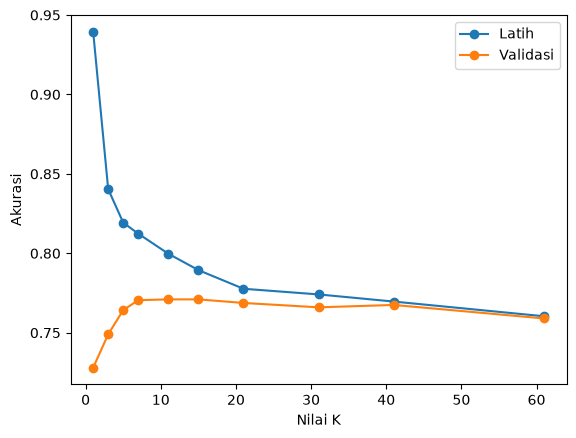

K terbaik: 11


,K,Akurasi latih,Akurasi validasi
0,1,0.940,0.728
1,3,0.840,0.749
2,5,0.819,0.764
3,7,0.812,0.770
4,11,0.800,0.771
5,15,0.789,0.771
6,21,0.778,0.769
7,31,0.774,0.766
8,41,0.770,0.768
9,61,0.760,0.759


In [3]:
# memilih K: K kecil sensitif terhadap noise, K besar terlalu kaku (nilai ganjil agar voting tidak seri)
daftar_K = [1, 3, 5, 7, 11, 15, 21, 31, 41, 61]
skor_latih, skor_val = [], []
for k in daftar_K:
    m = KNeighborsClassifier(n_neighbors=k).fit(X_fit, y_fit)
    skor_latih.append(m.score(X_fit, y_fit))
    skor_val.append(m.score(X_val, y_val))

plt.plot(daftar_K, skor_latih, marker="o", label="Latih")
plt.plot(daftar_K, skor_val, marker="o", label="Validasi")
plt.xlabel("Nilai K")
plt.ylabel("Akurasi")
plt.legend()
plt.show()

K_terbaik = daftar_K[int(np.argmax(skor_val))]
print("K terbaik:", K_terbaik)
pd.DataFrame({"K": daftar_K, "Akurasi latih": skor_latih, "Akurasi validasi": skor_val}).round(3)

In [4]:
# lazy learning: KNN hampir tidak butuh waktu latih, tetapi lambat saat prediksi (dibandingkan SVM yang eager)
pre_akhir = clone(pre).fit(train)
X_train, X_test = pre_akhir.transform(train), pre_akhir.transform(test)
y_train, y_test = train["kelas_utama"], test["kelas_utama"]

model = {"KNN": KNeighborsClassifier(n_neighbors=K_terbaik), "SVM": LinearSVC(random_state=42)}
hasil = []
for nama, m in model.items():
    t = time.time()
    m.fit(X_train, y_train)
    w_latih = time.time() - t
    t = time.time()
    pred = m.predict(X_test)
    w_prediksi = time.time() - t
    hasil.append({"Model": nama, "Waktu latih (detik)": w_latih, "Waktu prediksi (detik)": w_prediksi,
                  "Akurasi uji": (pred == y_test).mean()})
pd.DataFrame(hasil).round(3)

,Model,Waktu latih (detik),Waktu prediksi (detik),Akurasi uji
0,KNN,0.018,6.205,0.775
1,SVM,0.211,0.000,0.808


In [5]:
# butuh memori besar: KNN menyimpan seluruh data latih, SVM hanya menyimpan bobot
data_knn = X_train.data.nbytes + X_train.indices.nbytes + X_train.indptr.nbytes
bobot_svm = model["SVM"].coef_.nbytes
print(f"Memori KNN (data latih tersimpan): {data_knn / 1024:.0f} KB")
print(f"Memori SVM (bobot model): {bobot_svm / 1024:.0f} KB")

Memori KNN (data latih tersimpan): 1804 KB
Memori SVM (bobot model): 7 KB


In [6]:
# sensitif terhadap skala: fitur dengan rentang besar mendominasi jarak
mentah = fit_df[num_cols].to_numpy(dtype=float)
skala = MinMaxScaler().fit(mentah)
rng = np.random.default_rng(42)
a, b = rng.integers(0, len(mentah), 5000), rng.integers(0, len(mentah), 5000)

kontribusi = pd.DataFrame(index=num_cols)
for nama, x in {"Tanpa scaling": mentah, "Dengan scaling": skala.transform(mentah)}.items():
    selisih = (x[a] - x[b]) ** 2
    kontribusi[nama] = selisih.mean(axis=0) / selisih.mean(axis=0).sum()
print("Kontribusi tiap fitur pada jarak:")
print((kontribusi * 100).round(1))

y_tr, y_va = y_fit, y_val
for nama, f in {"Tanpa scaling": lambda x: x, "Dengan scaling": skala.transform}.items():
    m_skala = KNeighborsClassifier(n_neighbors=K_terbaik).fit(f(mentah), y_tr)
    print(f"Akurasi validasi {nama}: {m_skala.score(f(val_df[num_cols].to_numpy(dtype=float)), y_va):.1%}")

Kontribusi tiap fitur pada jarak:
                   Tanpa scaling  Dengan scaling
suku_kata                    0.1             3.6
huruf                        0.4             3.9
panjang_makna               97.6             2.8
jumlah_kata_makna            1.9             2.9
ada_contoh                   0.0            86.8
Akurasi validasi Tanpa scaling: 70.5%
Akurasi validasi Dengan scaling: 71.1%


In [7]:
# kutukan dimensi: akurasi KNN ketika jumlah fitur (kata) bertambah
hasil = []
for n in [50, 300, 1000, 3000]:
    v = TfidfVectorizer(max_features=n, min_df=2).fit(fit_df["submakna"])
    m_dim = KNeighborsClassifier(n_neighbors=K_terbaik).fit(v.transform(fit_df["submakna"]), y_fit)
    hasil.append({"Jumlah fitur": n, "Akurasi validasi": m_dim.score(v.transform(val_df["submakna"]), y_val)})
pd.DataFrame(hasil).round(3)

,Jumlah fitur,Akurasi validasi
0,50,0.680
1,300,0.713
2,1000,0.688
3,3000,0.606


### Analisis

Pada contoh manual, empat dari lima tetangga terdekat berkelas verba sehingga prediksinya verba, sama dengan hasil KNeighborsClassifier dan kelas sebenarnya. Pada pemilihan K, K=1 menghafal data latih (akurasi latih 94,0 persen) tetapi akurasi validasinya hanya 72,7 persen karena terlalu sensitif terhadap tetangga yang aneh. Akurasi validasi naik sampai K=15 (77,2 persen) lalu turun pelan ke 76,0 persen pada K=61 karena pilihan suara menjadi terlalu rata-rata. Karena itu K=15 dipakai, dan akurasi uji akhirnya 77,1 persen.

Sifat lazy learning terlihat jelas. KNN hanya butuh sekitar 0,02 detik untuk dilatih tetapi lebih dari 10 detik untuk memprediksi 19.857 data uji, sedangkan SVM butuh 0,2 detik untuk dilatih dan 0,002 detik untuk memprediksi, dengan akurasi uji lebih tinggi (80,7 persen). KNN juga harus menyimpan seluruh data latih (sekitar 1.800 KB) sementara bobot SVM hanya sekitar 7 KB.

Soal skala, tanpa scaling 97,6 persen jarak ditentukan oleh panjang_makna saja, sehingga fitur lain nyaris tidak dihitung. Setelah scaling, dominasi panjang_makna hilang dan akurasi validasi naik dari 70,2 ke 71,4 persen, tetapi jarak kini lebih banyak ditentukan oleh ada_contoh (86,8 persen) karena fitur ini bernilai 0 atau 1 sedangkan fitur lain sebagian besar bernilai kecil. Jadi scaling perlu, tetapi belum cukup untuk membuat semua fitur berperan sama. Kutukan dimensi juga terlihat: akurasi validasi tertinggi di 300 fitur (70,8 persen) lalu turun menjadi 64,4 persen pada 3.000 fitur, kebalikan dari SVM yang makin baik dengan fitur lebih banyak.

In [8]:
# refleksi: sistem rekomendasi "Orang yang Mungkin Anda Kenal"
pd.DataFrame({
    "Pertanyaan": ["Data latih", "Jarak", "Keputusan KNN (K=10)"],
    "Jawaban": ["Jutaan pengguna lain di platform",
                "Kesamaan, misalnya jumlah teman yang sama, sekolah, tempat kerja, dan grup",
                "Cari 10 pengguna paling mirip, lalu rekomendasikan teman mereka yang belum berteman dengan Anda"],
})

,Pertanyaan,Jawaban
0,Data latih,Jutaan pengguna lain di platform
1,Jarak,"Kesamaan, misalnya jumlah teman yang sama, sek..."
2,Keputusan KNN (K=10),"Cari 10 pengguna paling mirip, lalu rekomendas..."
